In [1]:
import pandas as pd
import numpy as np

In [2]:
df_master_produk = pd.read_csv('master_produk.csv')
df_orders = pd.read_csv('orders.csv')

In [3]:
df_master_produk.head()

,id_produk,nama_produk,kategori,harga
0,P001,Earphone,Elektronik,45000
1,P002,Powerbank,Elektronik,25000
2,P003,Mouse,Elektronik,120000
3,P004,Keyboard,Elektronik,85000
4,P005,Webcam,Elektronik,85000


In [4]:
df_master_produk.isna().sum()

id_produk      0
nama_produk    0
kategori       0
harga          0
dtype: int64

In [5]:
df_master_produk.info()

<class 'pandas.DataFrame'>
RangeIndex: 20 entries, 0 to 19
Data columns (total 4 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   id_produk    20 non-null     str  
 1   nama_produk  20 non-null     str  
 2   kategori     20 non-null     str  
 3   harga        20 non-null     int64
dtypes: int64(1), str(3)
memory usage: 772.0 bytes


In [6]:
df_orders

,order_id,tanggal,id_customer,id_produk,qty,diskon_persen,kota,metode_bayar,status,rating
0,ORD0115,2026-01-22,C032,P019,2,10.0,MAKASSAR,E-Wallet,selesai,1.0
1,ORD0174,16/08/2026,C011,P019,1,0.0,Palembang,Transfer,Selesai,4.0
2,ORD0239,11-Aug-2026,C015,P011,5,10.0,makassar,COD,selesai,NaN
3,ORD0203,12-Apr-2026,C030,P005,1,5.0,jakarta,Kartu Kredit,Selesai,NaN
4,ORD0277,03-May-2026,C048,P017,1,15.0,Makassar,E-Wallet,selesai,3.0
...,...,...,...,...,...,...,...,...,...,...
307,ORD0118,17-Jun-2026,C002,P007,1,10.0,Jakarta,Kartu Kredit,batal,5.0
308,ORD0295,05/05/2026,C005,P015,5,10.0,palembang,COD,Dikirim,NaN
309,ORD0068,16-May-2026,C015,P012,2,5.0,Palembang,E-Wallet,selesai,NaN
310,ORD0293,26-May-2026,C030,P019,3,0.0,Palembang,E-Wallet,Batal,4.0


In [7]:
df_orders.isna().sum()

order_id          0
tanggal           0
id_customer       0
id_produk         0
qty              12
diskon_persen    38
kota              0
metode_bayar      0
status            0
rating           75
dtype: int64

In [8]:
df_orders.describe()

,diskon_persen,rating
count,274.000000,237.000000
mean,8.083942,3.506329
std,7.037073,1.354904
min,0.000000,1.000000
25%,0.000000,2.000000
50%,5.000000,4.000000
75%,15.000000,5.000000
max,20.000000,5.000000


In [9]:
df_orders.info()

<class 'pandas.DataFrame'>
RangeIndex: 312 entries, 0 to 311
Data columns (total 10 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   order_id       312 non-null    str    
 1   tanggal        312 non-null    str    
 2   id_customer    312 non-null    str    
 3   id_produk      312 non-null    str    
 4   qty            300 non-null    str    
 5   diskon_persen  274 non-null    float64
 6   kota           312 non-null    str    
 7   metode_bayar   312 non-null    str    
 8   status         312 non-null    str    
 9   rating         237 non-null    float64
dtypes: float64(2), str(8)
memory usage: 24.5 KB


In [10]:
df_orders['tanggal'] = pd.to_datetime(df_orders['tanggal'], format='mixed', errors='coerce')
df_orders['qty'] = pd.to_numeric(df_orders['qty'], errors='coerce')
df_orders['kota'] = df_orders['kota'].str.title().str.strip() 
df_orders['status'] = df_orders['status'].str.title().str.strip() 
df_orders['diskon_persen'] = df_orders['diskon_persen'].fillna(
    df_orders.groupby('qty')['diskon_persen'].transform('median')
)
df_orders['diskon_persen'].value_counts(dropna=False)

diskon_persen
0.0     79
5.0     77
10.0    71
20.0    41
15.0    36
7.5      5
NaN      3
Name: count, dtype: int64

In [11]:
df_orders.head()

,order_id,tanggal,id_customer,id_produk,qty,diskon_persen,kota,metode_bayar,status,rating
0,ORD0115,2026-01-22,C032,P019,2.0,10.0,Makassar,E-Wallet,Selesai,1.0
1,ORD0174,2026-08-16,C011,P019,1.0,0.0,Palembang,Transfer,Selesai,4.0
2,ORD0239,2026-08-11,C015,P011,5.0,10.0,Makassar,COD,Selesai,NaN
3,ORD0203,2026-04-12,C030,P005,1.0,5.0,Jakarta,Kartu Kredit,Selesai,NaN
4,ORD0277,2026-05-03,C048,P017,1.0,15.0,Makassar,E-Wallet,Selesai,3.0


In [12]:
df_orders.isna().sum()

order_id          0
tanggal           0
id_customer       0
id_produk         0
qty              20
diskon_persen     3
kota              0
metode_bayar      0
status            0
rating           75
dtype: int64

In [13]:
left_join = df_orders.merge(df_master_produk, on='id_produk', how='left')

left_join

,order_id,tanggal,id_customer,id_produk,qty,diskon_persen,kota,metode_bayar,status,rating,nama_produk,kategori,harga
0,ORD0115,2026-01-22,C032,P019,2.0,10.0,Makassar,E-Wallet,Selesai,1.0,Masker,Kecantikan,85000.0
1,ORD0174,2026-08-16,C011,P019,1.0,0.0,Palembang,Transfer,Selesai,4.0,Masker,Kecantikan,85000.0
2,ORD0239,2026-08-11,C015,P011,5.0,10.0,Makassar,COD,Selesai,NaN,Rice Cooker,Rumah Tangga,25000.0
3,ORD0203,2026-04-12,C030,P005,1.0,5.0,Jakarta,Kartu Kredit,Selesai,NaN,Webcam,Elektronik,85000.0
4,ORD0277,2026-05-03,C048,P017,1.0,15.0,Makassar,E-Wallet,Selesai,3.0,Sunscreen,Kecantikan,25000.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
307,ORD0118,2026-06-17,C002,P007,1.0,10.0,Jakarta,Kartu Kredit,Batal,5.0,Hoodie,Fashion,45000.0
308,ORD0295,2026-05-05,C005,P015,5.0,10.0,Palembang,COD,Dikirim,NaN,Dispenser,Rumah Tangga,85000.0
309,ORD0068,2026-05-16,C015,P012,2.0,5.0,Palembang,E-Wallet,Selesai,NaN,Blender,Rumah Tangga,25000.0
310,ORD0293,2026-05-26,C030,P019,3.0,0.0,Palembang,E-Wallet,Batal,4.0,Masker,Kecantikan,85000.0


In [14]:
print(left_join.isna().sum())

order_id          0
tanggal           0
id_customer       0
id_produk         0
qty              20
diskon_persen     3
kota              0
metode_bayar      0
status            0
rating           75
nama_produk      11
kategori         11
harga            11
dtype: int64


In [15]:
left_join.loc[left_join['nama_produk'].isna(), 'id_produk'].unique()

<StringArray>
['P999']
Length: 1, dtype: str

In [16]:
print(len(left_join))
df = left_join.drop_duplicates()          
print(len(df))                     

312
300


In [17]:
print(df.isna().sum())

order_id          0
tanggal           0
id_customer       0
id_produk         0
qty              18
diskon_persen     2
kota              0
metode_bayar      0
status            0
rating           74
nama_produk      11
kategori         11
harga            11
dtype: int64


In [18]:
df['id_produk'].eq('P999').sum()
df['harga'].isna().sum()

np.int64(11)

In [19]:
df

,order_id,tanggal,id_customer,id_produk,qty,diskon_persen,kota,metode_bayar,status,rating,nama_produk,kategori,harga
0,ORD0115,2026-01-22,C032,P019,2.0,10.0,Makassar,E-Wallet,Selesai,1.0,Masker,Kecantikan,85000.0
1,ORD0174,2026-08-16,C011,P019,1.0,0.0,Palembang,Transfer,Selesai,4.0,Masker,Kecantikan,85000.0
2,ORD0239,2026-08-11,C015,P011,5.0,10.0,Makassar,COD,Selesai,NaN,Rice Cooker,Rumah Tangga,25000.0
3,ORD0203,2026-04-12,C030,P005,1.0,5.0,Jakarta,Kartu Kredit,Selesai,NaN,Webcam,Elektronik,85000.0
4,ORD0277,2026-05-03,C048,P017,1.0,15.0,Makassar,E-Wallet,Selesai,3.0,Sunscreen,Kecantikan,25000.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
307,ORD0118,2026-06-17,C002,P007,1.0,10.0,Jakarta,Kartu Kredit,Batal,5.0,Hoodie,Fashion,45000.0
308,ORD0295,2026-05-05,C005,P015,5.0,10.0,Palembang,COD,Dikirim,NaN,Dispenser,Rumah Tangga,85000.0
309,ORD0068,2026-05-16,C015,P012,2.0,5.0,Palembang,E-Wallet,Selesai,NaN,Blender,Rumah Tangga,25000.0
310,ORD0293,2026-05-26,C030,P019,3.0,0.0,Palembang,E-Wallet,Batal,4.0,Masker,Kecantikan,85000.0


In [20]:
df['bulan'] = df['tanggal'].dt.month            # 1-12
df['hari_dalam_minggu'] = df['tanggal'].dt.day_name()

In [21]:
df['total_bayar'] = df['qty'] * df['harga'] * (1 - df['diskon_persen'] / 100)

df

,order_id,tanggal,id_customer,id_produk,qty,diskon_persen,kota,metode_bayar,status,rating,nama_produk,kategori,harga,bulan,hari_dalam_minggu,total_bayar
0,ORD0115,2026-01-22,C032,P019,2.0,10.0,Makassar,E-Wallet,Selesai,1.0,Masker,Kecantikan,85000.0,1,Thursday,153000.0
1,ORD0174,2026-08-16,C011,P019,1.0,0.0,Palembang,Transfer,Selesai,4.0,Masker,Kecantikan,85000.0,8,Sunday,85000.0
2,ORD0239,2026-08-11,C015,P011,5.0,10.0,Makassar,COD,Selesai,NaN,Rice Cooker,Rumah Tangga,25000.0,8,Tuesday,112500.0
3,ORD0203,2026-04-12,C030,P005,1.0,5.0,Jakarta,Kartu Kredit,Selesai,NaN,Webcam,Elektronik,85000.0,4,Sunday,80750.0
4,ORD0277,2026-05-03,C048,P017,1.0,15.0,Makassar,E-Wallet,Selesai,3.0,Sunscreen,Kecantikan,25000.0,5,Sunday,21250.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
307,ORD0118,2026-06-17,C002,P007,1.0,10.0,Jakarta,Kartu Kredit,Batal,5.0,Hoodie,Fashion,45000.0,6,Wednesday,40500.0
308,ORD0295,2026-05-05,C005,P015,5.0,10.0,Palembang,COD,Dikirim,NaN,Dispenser,Rumah Tangga,85000.0,5,Tuesday,382500.0
309,ORD0068,2026-05-16,C015,P012,2.0,5.0,Palembang,E-Wallet,Selesai,NaN,Blender,Rumah Tangga,25000.0,5,Saturday,47500.0
310,ORD0293,2026-05-26,C030,P019,3.0,0.0,Palembang,E-Wallet,Batal,4.0,Masker,Kecantikan,85000.0,5,Tuesday,255000.0


In [22]:
df['status'] = df['status'].str.strip().str.lower()
df['status'].unique()        

<StringArray>
['selesai', 'batal', 'dikirim']
Length: 3, dtype: str

In [23]:
df_selesai = df[df['status'] == 'selesai']

In [24]:
print(len(df), len(df_selesai))
df_selesai['status'].unique()    

300 187


<StringArray>
['selesai']
Length: 1, dtype: str

In [25]:
df_selesai = df[df['status'] == 'selesai'].copy()

In [26]:
t = pd.read_csv('orders.csv')['tanggal']     

d1 = pd.to_datetime(t, format='%Y-%m-%d', errors='coerce')
d2 = pd.to_datetime(t, format='%d/%m/%Y', errors='coerce')
d3 = pd.to_datetime(t, format='%d-%b-%Y', errors='coerce')

df['tanggal'] = d1.fillna(d2).fillna(d3)     
df['bulan'] = df['tanggal'].dt.month         

In [27]:
df['tanggal'].isna().sum()                   # harus 0
df['bulan'].value_counts().sort_index()      # harus 1 sampai 9 doang

bulan
1    27
2    28
3    31
4    29
5    49
6    37
7    38
8    33
9    28
Name: count, dtype: int64

In [28]:
df_selesai = df[df['status'] == 'selesai'].copy()

In [29]:
df_selesai

,order_id,tanggal,id_customer,id_produk,qty,diskon_persen,kota,metode_bayar,status,rating,nama_produk,kategori,harga,bulan,hari_dalam_minggu,total_bayar
0,ORD0115,2026-01-22,C032,P019,2.0,10.0,Makassar,E-Wallet,selesai,1.0,Masker,Kecantikan,85000.0,1,Thursday,153000.0
1,ORD0174,2026-08-16,C011,P019,1.0,0.0,Palembang,Transfer,selesai,4.0,Masker,Kecantikan,85000.0,8,Sunday,85000.0
2,ORD0239,2026-08-11,C015,P011,5.0,10.0,Makassar,COD,selesai,NaN,Rice Cooker,Rumah Tangga,25000.0,8,Tuesday,112500.0
3,ORD0203,2026-04-12,C030,P005,1.0,5.0,Jakarta,Kartu Kredit,selesai,NaN,Webcam,Elektronik,85000.0,4,Sunday,80750.0
4,ORD0277,2026-05-03,C048,P017,1.0,15.0,Makassar,E-Wallet,selesai,3.0,Sunscreen,Kecantikan,25000.0,5,Sunday,21250.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
304,ORD0121,2026-07-11,C003,P012,1.0,15.0,Bandung,Kartu Kredit,selesai,NaN,Blender,Rumah Tangga,25000.0,7,Saturday,21250.0
305,ORD0139,2026-07-15,C056,P013,4.0,15.0,Surabaya,COD,selesai,NaN,Lampu LED,Rumah Tangga,45000.0,7,Wednesday,153000.0
306,ORD0052,2026-09-09,C027,P014,3.0,5.0,Makassar,E-Wallet,selesai,NaN,Sapu,Rumah Tangga,85000.0,9,Wednesday,242250.0
309,ORD0068,2026-05-16,C015,P012,2.0,5.0,Palembang,E-Wallet,selesai,NaN,Blender,Rumah Tangga,25000.0,5,Saturday,47500.0


In [30]:
'''Analisis & Visualisasi status = selesai'''

import matplotlib.pyplot as plt

In [31]:
'''total pendapatan per kategori'''

pendapatan_per_kategori = df_selesai.groupby('kategori')['total_bayar'].sum().sort_values(ascending=False).reset_index(name='pendapatan')

pendapatan_per_kategori

,kategori,pendapatan
0,Kecantikan,28381000.0
1,Fashion,14066250.0
2,Elektronik,6842250.0
3,Rumah Tangga,5709750.0


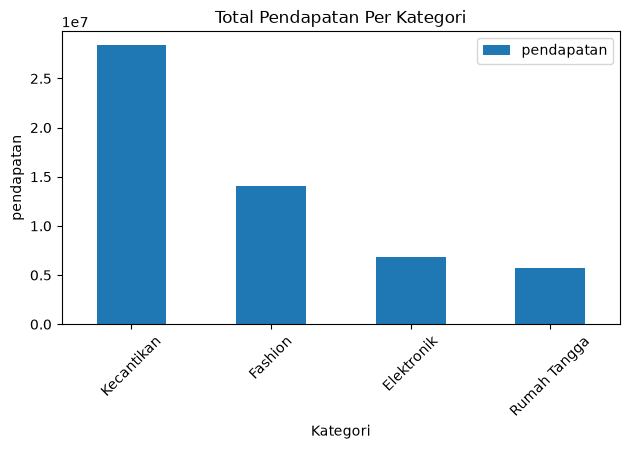

In [32]:
pendapatan_per_kategori.plot(kind='bar', x='kategori', y='pendapatan', title='Total Pendapatan Per Kategori')

plt.xlabel('Kategori')
plt.ylabel('pendapatan')
plt.tight_layout()
plt.xticks(rotation=45)

plt.show()

In [33]:
'''tren pendapatan per bulan'''

pendapatan_per_bulan = df_selesai.groupby('bulan')['total_bayar'].sum().sort_index().reset_index(name='pendapatan')

pendapatan_per_bulan

,bulan,pendapatan
0,1,4816750.0
1,2,7506750.0
2,3,7589250.0
3,4,3127250.0
4,5,5538000.0
5,6,5308750.0
6,7,6685000.0
7,8,7336000.0
8,9,7091500.0


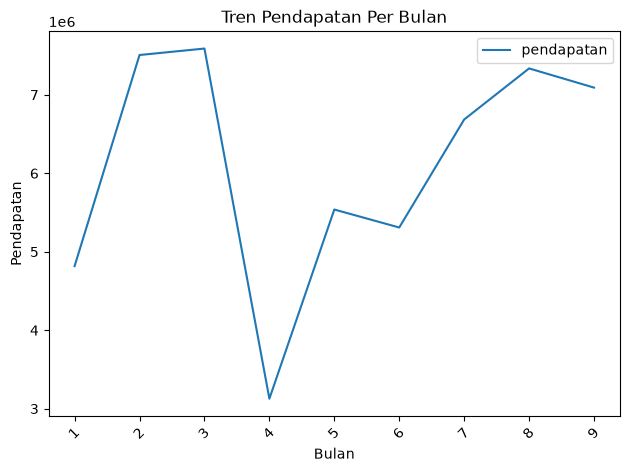

In [34]:
pendapatan_per_bulan.plot(kind='line', x='bulan', y='pendapatan', title='Tren Pendapatan Per Bulan')

plt.xlabel('Bulan')
plt.ylabel('Pendapatan')
plt.tight_layout()
plt.xticks(rotation=45)

plt.show()

In [35]:
'''5 produk terlaris berdasarkan total qty'''

lima_produk_terlaris = df_selesai.groupby('nama_produk')['qty'].sum().nlargest(5).sort_values(ascending=False)

lima_produk_terlaris

nama_produk
Mouse     33.0
Sapu      32.0
Hoodie    27.0
Serum     27.0
Topi      26.0
Name: qty, dtype: float64

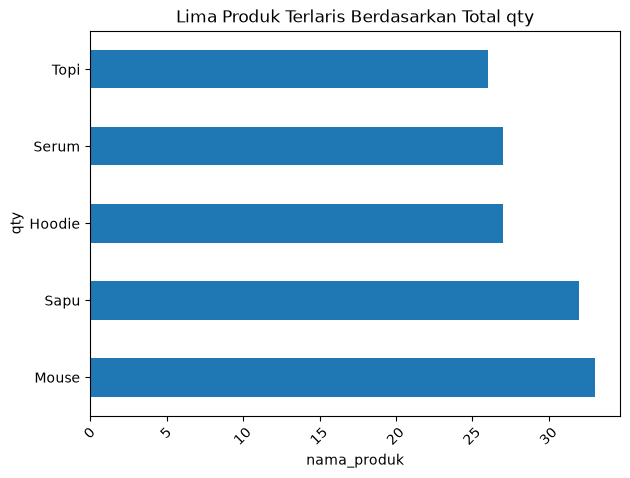

In [36]:
lima_produk_terlaris.plot(kind='barh', x='nama_produk', y='qty', title='Lima Produk Terlaris Berdasarkan Total qty')

plt.xlabel('nama_produk')
plt.ylabel('qty')
plt.tight_layout()
plt.xticks(rotation=45)

plt.show()

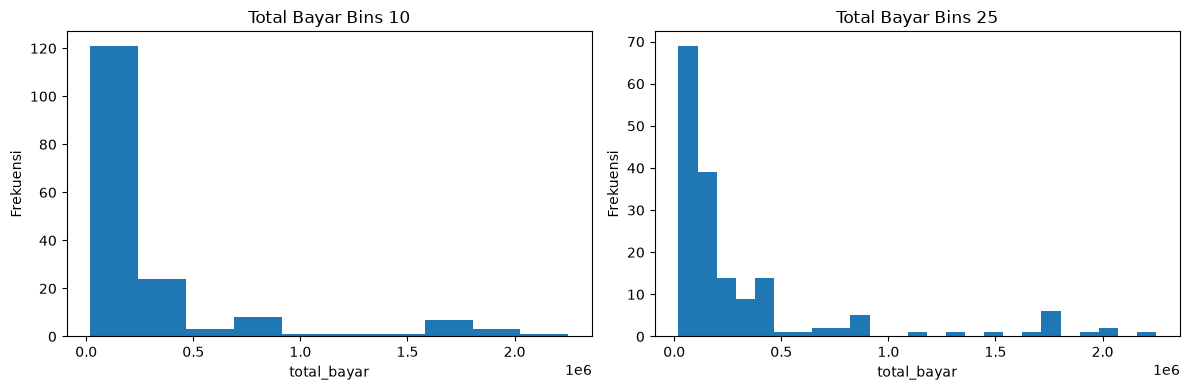

In [37]:
'''Distribusi total_bayar'''

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(df_selesai['total_bayar'], bins=10)
axes[0].set_title('Total Bayar Bins 10')
axes[0].set_xlabel('total_bayar')
axes[0].set_ylabel('Frekuensi')

axes[1].hist(df_selesai['total_bayar'], bins=25)
axes[1].set_title('Total Bayar Bins 25')
axes[1].set_xlabel('total_bayar')
axes[1].set_ylabel('Frekuensi')

plt.tight_layout()
plt.show()

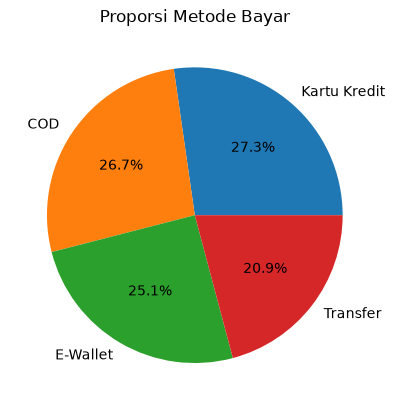

In [ ]:
'''Proporsi Metode Bayar'''

proporsi_metode_bayar = df_selesai['metode_bayar'].value_counts()

proporsi_metode_bayar.plot(kind='pie', labels=proporsi_metode_bayar.index, autopct='%1.1f%%')
plt.title('Proporsi Metode Bayar')

plt.show()

In [41]:
'''Pivot Table rata-rata rating per kategori'''

pivot_rating = df_selesai.groupby(['kategori', 'kota'])['rating'].mean().unstack().round(0)

pivot_rating

kota,Bandung,Jakarta,Makassar,Medan,Palembang,Surabaya
kategori,,,,,,
Elektronik,4.0,4.0,4.0,3.0,4.0,4.0
Fashion,4.0,4.0,3.0,3.0,3.0,3.0
Kecantikan,3.0,3.0,3.0,4.0,3.0,4.0
Rumah Tangga,4.0,5.0,4.0,1.0,4.0,3.0


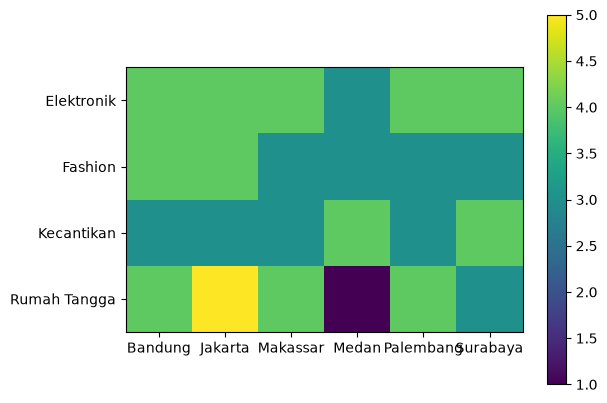

In [42]:
fig, ax = plt.subplots()
im = ax.imshow(pivot_rating.values)
ax.set_xticks(range(len(pivot_rating.columns)), pivot_rating.columns)
ax.set_yticks(range(len(pivot_rating.index)), pivot_rating.index)
plt.colorbar(im)

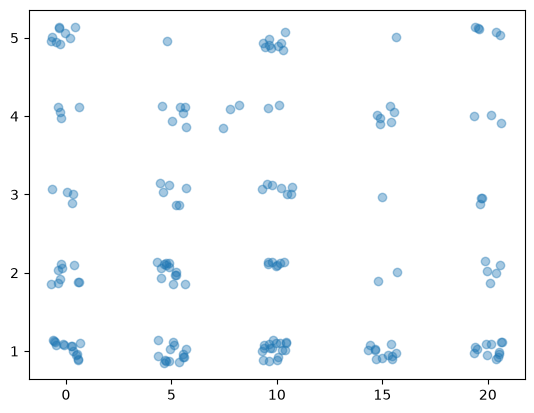

In [44]:
'''Scatter: diskon_persen vs qty'''

x = df_selesai['diskon_persen'] + np.random.uniform(-0.7, 0.7, len(df_selesai))
y = df_selesai['qty'] + np.random.uniform(-0.15, 0.15, len(df_selesai))
plt.scatter(x, y, alpha=0.4)

In [46]:
print(df_selesai[['diskon_persen', 'qty']].corr())

               diskon_persen       qty
diskon_persen       1.000000 -0.033178
qty                -0.033178  1.000000


In [55]:
'''rasio status order (selesai/batal/dikirim)'''

status_count = df['status'].value_counts()                  
status_rasio = df['status'].value_counts(normalize=True)    

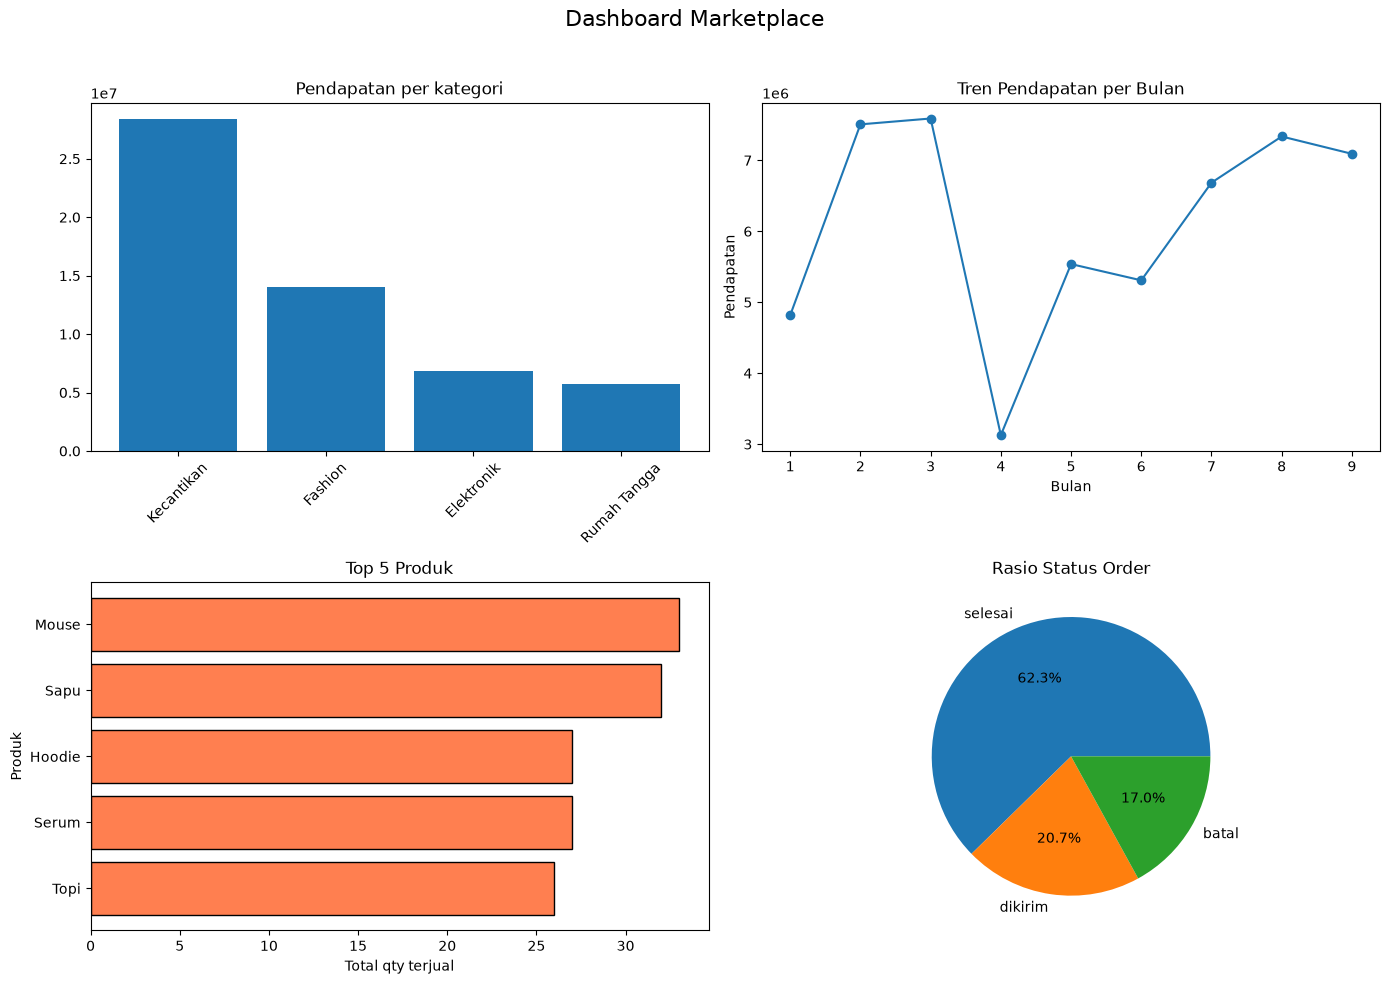

In [58]:
'''Dashboard Akhir'''

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle('Dashboard Marketplace', fontsize=16)

axes[0, 0].bar(pendapatan_per_kategori['kategori'], pendapatan_per_kategori['pendapatan'])
axes[0, 0].set_title('Pendapatan per kategori')
axes[0, 0].tick_params(axis='x', rotation=45)

axes[0, 1].plot(pendapatan_per_bulan['bulan'], pendapatan_per_bulan['pendapatan'], marker='o')
axes[0, 1].set_title('Tren Pendapatan per Bulan')
axes[0, 1].set_xlabel('Bulan')
axes[0, 1].set_ylabel('Pendapatan')

axes[1, 0].barh(lima_produk_terlaris.index, lima_produk_terlaris.values,
                color='coral', edgecolor='black')
axes[1, 0].set_title('Top 5 Produk')
axes[1, 0].set_xlabel('Total qty terjual')
axes[1, 0].set_ylabel('Produk')
axes[1, 0].invert_yaxis()   


axes[1, 1].pie(status_count.values, labels=status_count.index, autopct='%1.1f%%')
axes[1, 1].set_title('Rasio Status Order')

plt.tight_layout(rect=[0, 0, 1, 0.96])
fig.savefig('dashboard_marketplace.png', dpi=150, bbox_inches='tight')
plt.show()